<h1><center> Predict Position Salaries

In [87]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [88]:
data = pd.read_csv('Position_Salaries.csv')
print("Les données sont chargées avec succées!")

Les données sont chargées avec succées!


In [89]:
data.head()

,Position,Level,Salary
0,Business Analyst,1,45000
1,Junior Consultant,2,50000
2,Senior Consultant,3,60000
3,Manager,4,80000
4,Country Manager,5,110000


In [90]:
data.describe()

,Level,Salary
count,10.00000,10.000000
mean,5.50000,249500.000000
std,3.02765,299373.883668
min,1.00000,45000.000000
25%,3.25000,65000.000000
50%,5.50000,130000.000000
75%,7.75000,275000.000000
max,10.00000,1000000.000000


In [91]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Position  10 non-null     object
 1   Level     10 non-null     int64 
 2   Salary    10 non-null     int64 
dtypes: int64(2), object(1)
memory usage: 368.0+ bytes


In [92]:
# Les données nulles
data.isnull().sum()

Position    0
Level       0
Salary      0
dtype: int64

In [93]:
# Les données dupliquées
data.duplicated().sum()

0

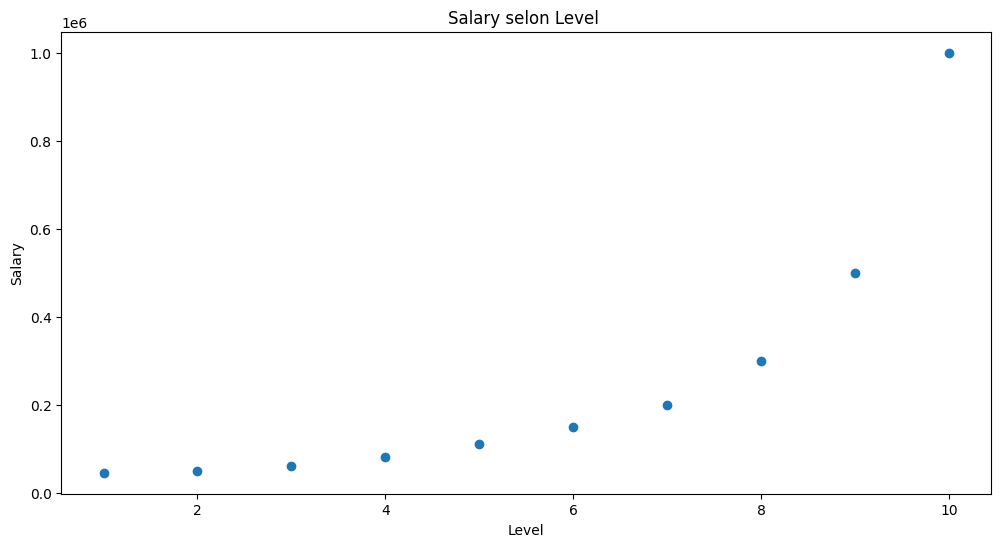

In [94]:
plt.figure(figsize=(12,6))
plt.scatter(data= data, x= 'Level', y ='Salary')
plt.xlabel('Level')
plt.ylabel('Salary')
plt.title('Salary selon Level ')
plt.show()

In [95]:
data['Position'].value_counts()

Business Analyst     1
Junior Consultant    1
Senior Consultant    1
Manager              1
Country Manager      1
Region Manager       1
Partner              1
Senior Partner       1
C-level              1
CEO                  1
Name: Position, dtype: int64

In [96]:
# Définir X et y
X= data[['Level']]
y = data[['Salary']]

In [97]:
poly = PolynomialFeatures(degree= 4, include_bias= False)
poly

PolynomialFeatures(degree=4, include_bias=False)

In [98]:
features_poly = poly.fit_transform(X)

In [99]:
# création du modéle régression linéaire

model = LinearRegression()
model

LinearRegression()

In [100]:
model.fit(features_poly, y)

LinearRegression()

In [101]:
y_predict = model.predict(features_poly)
y_predict

array([[ 53356.64335663],
       [ 31759.9067599 ],
       [ 58642.19114219],
       [ 94632.86713287],
       [121724.94172495],
       [143275.05827508],
       [184003.49650352],
       [289994.17249419],
       [528694.63869464],
       [988916.08391605]])

In [102]:
model.coef_

array([[-211002.33100234,   94765.44289045,  -15463.28671329,
            890.15151515]])

In [103]:
model.intercept_

array([184166.66666666])

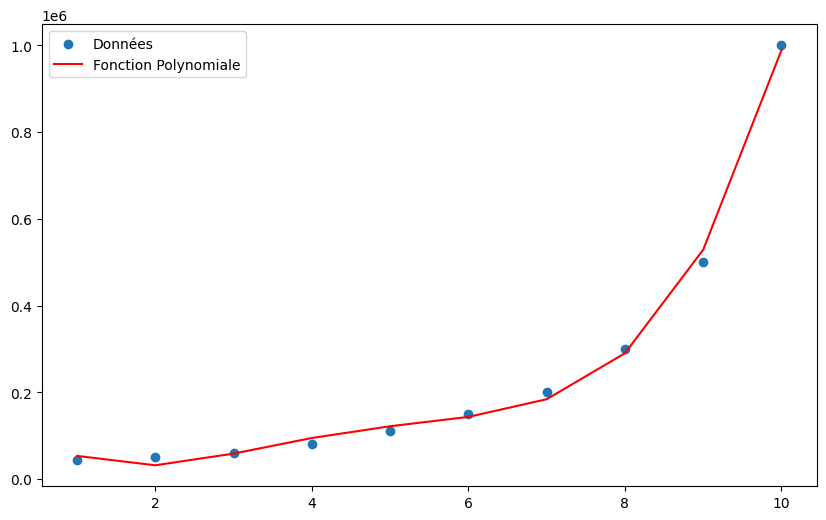

In [104]:
plt.figure(figsize=(10,6))
plt.scatter(X, y, label='Données')
plt.plot(X, y_predict, color= 'red', label='Fonction Polynomiale')
plt.legend()
plt.show()

In [105]:
r2 = r2_score(y, y_predict)
mse = mean_squared_error(y, y_predict)

print('R2 Score : ', r2)
print('Mean squared error : ', mse)
print('Root mean squared error : ', np.sqrt(mse))


R2 Score :  0.9973922891706614
Mean squared error :  210343822.84381735
Root mean squared error :  14503.234909626795


<h1><center> FIN